In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import yfinance as yf

In [21]:
tickers = {
    "FTSE": "^FTSE",
    "DAX": "^GDAXI",
    "SMI": "^SSMI",
    "CAC": "^FCHI"
}

raw = yf.download(
    list(tickers.values()),
    start="2018-01-01",
    auto_adjust=True,
    progress=False
)

data = raw["Close"]

data.columns = list(tickers.keys())

print(data.head())

                   FTSE          DAX           SMI          CAC
Date                                                           
2018-01-02  5288.600098  7648.100098  12871.389648          NaN
2018-01-03  5331.279785  7671.100098  12978.209961  9478.919922
2018-01-04  5413.689941  7695.899902  13167.889648  9509.280273
2018-01-05  5470.750000  7724.200195  13319.639648  9556.980469
2018-01-08  5487.419922  7696.500000  13367.780273  9541.730469


In [22]:
r = np.log(data / data.shift(1)).dropna()

print(r.head())

                FTSE       DAX       SMI       CAC
Date                                              
2018-01-04  0.015340  0.003228  0.014509  0.003198
2018-01-05  0.010485  0.003671  0.011458  0.005004
2018-01-08  0.003042 -0.003593  0.003608 -0.001597
2018-01-09  0.006633  0.004473  0.001331  0.007297
2018-01-10 -0.003493  0.002261 -0.007819 -0.009056


In [23]:
# Log returns in percentage terms
r = np.log(data / data.shift(1)).dropna() * 100

# Annual target return and risk free rate from the PDF
expected_return = 12.5 / 252
rf = 3 / 252

Sigma = r.cov()

print("Target daily return:", expected_return)
print("Risk free rate:", rf)
Sigma


Target daily return: 0.0496031746031746
Risk free rate: 0.011904761904761904


,FTSE,DAX,SMI,CAC
FTSE,1.360302,0.987630,1.300082,0.882826
DAX,0.987630,0.983525,0.983003,0.730579
SMI,1.300082,0.983003,1.456870,0.890265
CAC,0.882826,0.730579,0.890265,0.881888


In [24]:
# Annual target return = 12.5%
annual_target_return = 0.125

# Convert annual to daily
expected_return = annual_target_return / 252

# Risk-free rate = 3% annual
rf = 0.03 / 252

mu = r.mean().values
Sigma = r.cov().values

print("Target daily return:", expected_return)
print("Daily risk-free rate:", rf)

print("\nMean daily returns:")
print(pd.Series(mu, index=r.columns))

Target daily return: 0.000496031746031746
Daily risk-free rate: 0.00011904761904761905

Mean daily returns:
FTSE    0.026562
DAX     0.015510
SMI     0.029053
CAC     0.016314
dtype: float64


In [25]:
n_assets = len(mu)

def portfolio_variance(w):
    return w.T @ Sigma @ w

constraints = [
    {"type": "eq", "fun": lambda w: np.sum(w) - 1},
    {"type": "eq", "fun": lambda w: np.dot(w, mu) - expected_return}
]

bounds = tuple((0, 1) for _ in range(n_assets))

w0 = np.repeat(1/n_assets, n_assets)

result = minimize(
    portfolio_variance,
    w0,
    method="SLSQP",
    bounds=bounds,
    constraints=constraints
)

print(result.success)
print(result.message)

False
Positive directional derivative for linesearch


In [26]:
weights = pd.Series(
    result.x * 100,
    index=r.columns
)

print("Optimal Weights (%)")
print(weights.round(4))

Optimal Weights (%)
FTSE      0.0
DAX     100.0
SMI       0.0
CAC       0.0
dtype: float64


In [27]:
w = result.x

portfolio_return = np.dot(w, mu)

portfolio_volatility = np.sqrt(
    np.dot(w.T, np.dot(Sigma, w))
)

print("Expected Daily Return:", portfolio_return)
print("Daily Volatility:", portfolio_volatility)

print("Expected Annual Return:", portfolio_return * 252)
print("Annual Volatility:", portfolio_volatility * np.sqrt(252))

Expected Daily Return: 0.015510073910060998
Daily Volatility: 0.9917280764907166
Expected Annual Return: 3.9085386253353716
Annual Volatility: 15.74319515156927


In [28]:
target_returns = np.linspace(
    mu.min(),
    mu.max(),
    50
)

frontier_vol = []
frontier_ret = []

for target in target_returns:

    constraints = [
        {"type": "eq",
         "fun": lambda w: np.sum(w) - 1},

        {"type": "eq",
         "fun": lambda w, t=target:
                np.dot(w, mu) - t}
    ]

    res = minimize(
        portfolio_variance,
        w0,
        method="SLSQP",
        bounds=bounds,
        constraints=constraints
    )

    if res.success:

        vol = np.sqrt(
            np.dot(res.x.T,
                   np.dot(Sigma, res.x))
        )

        frontier_vol.append(vol)
        frontier_ret.append(target)

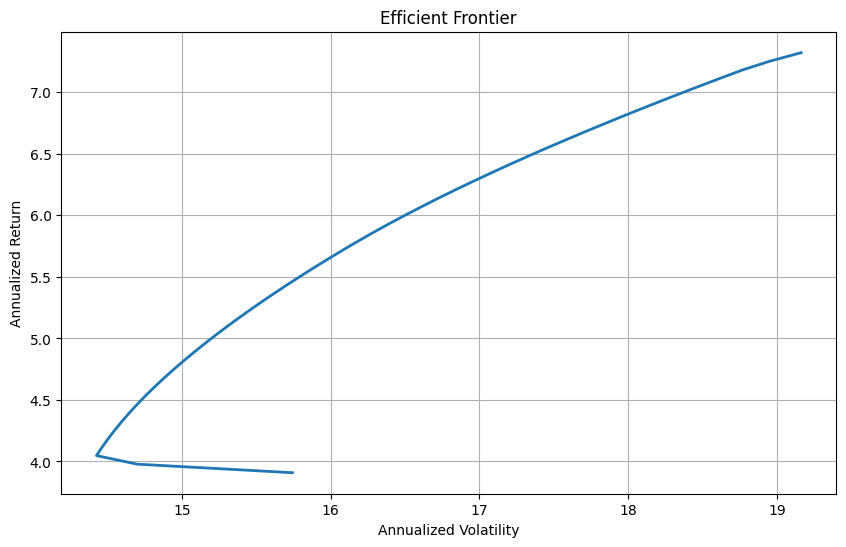

In [29]:
plt.figure(figsize=(10,6))

plt.plot(
    np.array(frontier_vol) * np.sqrt(252),
    np.array(frontier_ret) * 252,
    linewidth=2
)

plt.xlabel("Annualized Volatility")
plt.ylabel("Annualized Return")
plt.title("Efficient Frontier")

plt.grid(True)

plt.show()

In [30]:
def negative_sharpe(w):

    port_return = np.dot(w, mu)

    port_vol = np.sqrt(
        np.dot(w.T,
               np.dot(Sigma, w))
    )

    return -(port_return - rf) / port_vol


constraints = [
    {"type": "eq", "fun": lambda w: np.sum(w) - 1}
]

res = minimize(
    negative_sharpe,
    w0,
    method="SLSQP",
    bounds=bounds,
    constraints=constraints
)

sharpe_weights = pd.Series(
    res.x * 100,
    index=r.columns
)

print("Maximum Sharpe Portfolio")
print(sharpe_weights.round(2))

Maximum Sharpe Portfolio
FTSE    39.83
DAX      0.00
SMI     60.17
CAC      0.00
dtype: float64
